# 128 · Eval bug: before vs after (base300-v1@300)
**Bug:** with `torch.compile` (inductor, torch 2.11) the `no_grad` eval graph went wrong once a 2nd batch size appeared (the smaller last batch / a different split size): eval masks were wrong and **varied call-to-call** for the same checkpoint. Training was unaffected (grad graph fine).
**Fix:** `src9/run.py` now runs eval eager. Here the same ep300 checkpoint is re-evaluated eager on CPU (`runs/base300-v1-reeval`).
**Before** = the two buggy evals at batch 3000 in `runs/base300-v1/logs-rank0.txt` (in-fit eval, then post-fit `trainer.eval()`); **after** = the eager re-eval.

In [1]:
import os, sys, re
os.environ["CUDA_VISIBLE_DEVICES"] = ""
from pathlib import Path
from collections import defaultdict
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src9"))
from dataset import CATEGORIES
from score import truth
plt.rcParams.update({"font.size": 15, "axes.titlesize": 18, "axes.labelsize": 16, "legend.fontsize": 13})
RUN, EP = "base300-v1", 300
TAG = f"{RUN}@{EP}"
BOXES = ["gastro", "plastic", "cardboard"]
BOXC = {"gastro": "tab:blue", "plastic": "tab:orange", "cardboard": "tab:green"}
CAT = {(b, s): c for b, cs in CATEGORIES.items() for c, ss in cs.items() for s in ss}
pd.set_option("display.width", 250)

Failed to load CPU gemm_4bit_forward from kernels-community: No module named 'kernels'. Please make sure you already `pip install kernels` and the kernels >= 0.11.1


In [2]:
PAT = re.compile(r"^\[metric\]\[batch=(\d+)\]: metrics/eval/(\S+): ([-\d.eE+naif]+)")
def parse(path, batch=None):
    """{key: [values in log order]} for eval metrics at `batch` (None = last batch with eval metrics)"""
    rows = [(int(m[1]), m[2], float(m[3])) for l in open(path) if (m := PAT.match(l))]
    batch = max(b for b, _, _ in rows) if batch is None else batch
    out = defaultdict(list)
    for b, k, v in rows:
        if b == batch: out[k].append(v)
    return out, batch
old, _ = parse(ROOT / f"runs/{RUN}/logs-rank0.txt", 3000)
new, nb = parse(ROOT / f"runs/{RUN}-reeval/logs-rank0.txt")
print("old entries per key:", pd.Series([len(v) for v in old.values()]).value_counts().to_dict(), "| new:", pd.Series([len(v) for v in new.values()]).value_counts().to_dict(), "(new batch", nb, ")")
fit  = {k: v[0] for k, v in old.items()}
post = {k: v[-1] for k, v in old.items()}
aft  = {k: v[-1] for k, v in new.items()}

old entries per key: {2: 938} | new: {1: 938} (new batch 0 )


## Pooled table

In [3]:
MET = ["iou08", "miss08", "obj_recall", "biou"]
rows = []
for g in ["id", "ood", "core", "hard", "unseen_position", "unseen_angle"] + [f"{b}/{s}" for b in BOXES for s in ["id", "ood"]]:
    for m in MET:
        k = f"{g}/{m}"
        if k in aft and k in fit:
            rows.append(dict(group=g, metric=m, before_infit=fit[k], before_postfit=post[k], after=aft[k],
                             d_infit=aft[k] - fit[k], d_postfit=aft[k] - post[k]))
T = pd.DataFrame(rows)
print(f"{TAG}: before (buggy compiled eval) vs after (eager re-eval); d = after - before")
print(T.round(4).to_string(index=False))

base300-v1@300: before (buggy compiled eval) vs after (eager re-eval); d = after - before
          group     metric  before_infit  before_postfit  after  d_infit  d_postfit
             id      iou08        0.6669          0.6684 0.6800   0.0131     0.0116
            ood      iou08        0.3791          0.3810 0.3848   0.0057     0.0038
           core      iou08        0.7145          0.7158 0.7282   0.0137     0.0124
           core     miss08        0.0079          0.0091 0.0084   0.0005    -0.0007
           core obj_recall        0.9921          0.9909 0.9916  -0.0005     0.0007
           core       biou        0.5756          0.5760 0.5932   0.0176     0.0172
           hard      iou08        0.5479          0.5422 0.5578   0.0099     0.0156
           hard     miss08        0.0000          0.0000 0.0000   0.0000     0.0000
           hard obj_recall        1.0000          1.0000 1.0000   0.0000     0.0000
           hard       biou        0.4092          0.4013 0.4123   0.00

In [4]:
def splits(d, m="iou08"):
    out = {}
    for k, v in d.items():
        p = k.split("/")
        if len(p) == 3 and p[0] in BOXES and p[2] == m and p[1] not in ("id", "ood"): out[(p[0], p[1])] = v
    return out
S = pd.DataFrame({"before_infit": splits(fit), "before_postfit": splits(post), "after": splits(aft)}).dropna()
S.index.names = ["box", "split"]; S = S.reset_index()
S["cat"] = [CAT.get((b, s), "?") for b, s in zip(S.box, S.split)]
S["d"] = S.after - S.before_infit
S["d_post"] = S.after - S.before_postfit
S["d_fp"] = S.before_postfit - S.before_infit
for c, lab in [("d", "after - before(in-fit)"), ("d_post", "after - before(post-fit)"), ("d_fp", "before(post-fit) - before(in-fit)")]:
    print(f"{lab:36s} mean {S[c].mean():+.4f}  mean|.| {S[c].abs().mean():.4f}  max|.| {S[c].abs().max():.4f}  #after>before {(S[c] > 0).sum()}/{len(S)}")
print("\nworst |after - before(in-fit)|:")
print(S.reindex(S.d.abs().sort_values(ascending=False).index).head(10)[["box", "split", "cat", "before_infit", "before_postfit", "after", "d", "d_post"]].round(4).to_string(index=False))

after - before(in-fit)               mean +0.0097  mean|.| 0.0139  max|.| 0.1176  #after>before 47/65
after - before(post-fit)             mean +0.0076  mean|.| 0.0112  max|.| 0.0709  #after>before 42/65
before(post-fit) - before(in-fit)    mean +0.0021  mean|.| 0.0116  max|.| 0.0742  #after>before 36/65

worst |after - before(in-fit)|:
      box                      split             cat  before_infit  before_postfit  after       d  d_post
cardboard                  glass-cup         control        0.3500          0.3967 0.4676  0.1176  0.0709
cardboard             cylinder-1000g        cylinder        0.1500          0.2242 0.2448  0.0948  0.0206
cardboard            unseen-position unseen-position        0.4654          0.4860 0.5037  0.0383  0.0177
cardboard vase-unseen-speaker-unseen  unseen-speaker        0.3898          0.3704 0.3539 -0.0359 -0.0165
cardboard           glass-cup-broken          broken        0.2395          0.2873 0.2742  0.0347 -0.0131
cardboard               c

## Fig 1 · per-split iou08, before vs after

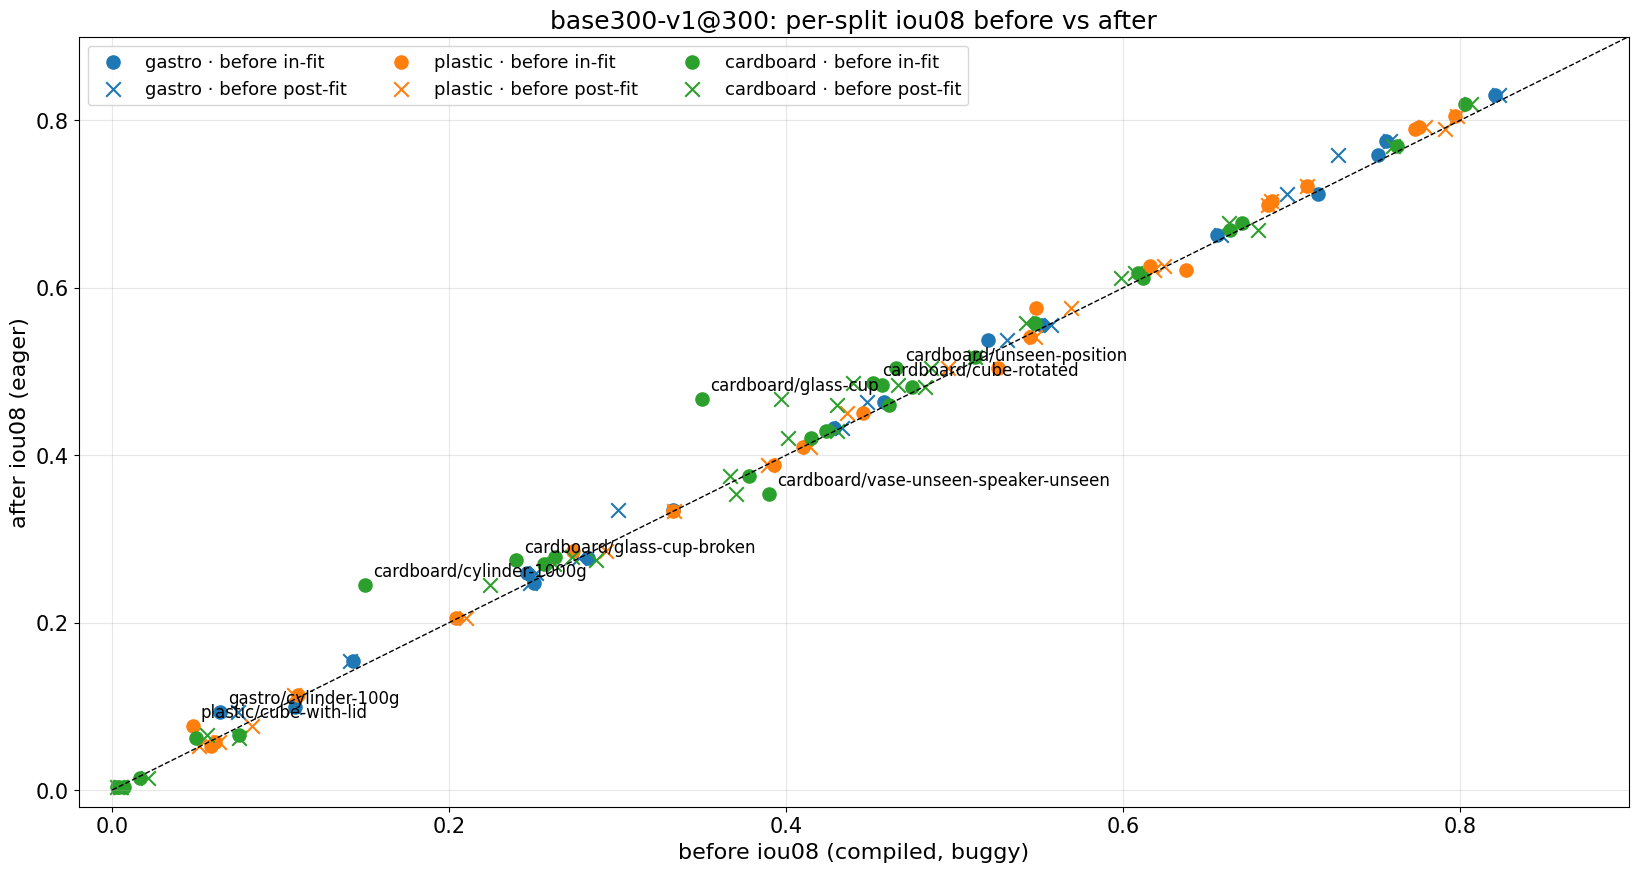

In [5]:
fig, ax = plt.subplots(figsize=(20, 10))
for b in BOXES:
    s = S[S.box == b]
    ax.scatter(s.before_infit, s.after, s=90, c=BOXC[b], marker="o", label=f"{b} · before in-fit")
    ax.scatter(s.before_postfit, s.after, s=110, c=BOXC[b], marker="x", label=f"{b} · before post-fit")
ax.plot([0, 1], [0, 1], "k--", lw=1)
for _, r in S.reindex(S.d.abs().sort_values(ascending=False).index).head(8).iterrows():
    ax.annotate(f"{r.box}/{r.split}", (r.before_infit, r.after), xytext=(6, 6), textcoords="offset points", fontsize=12)
ax.set(xlabel="before iou08 (compiled, buggy)", ylabel="after iou08 (eager)", title=f"{TAG}: per-split iou08 before vs after", xlim=(-0.02, 0.9), ylim=(-0.02, 0.9))
ax.legend(ncol=3); ax.grid(alpha=.3); plt.show()

## Fig 2 · per-split delta (after − before in-fit)

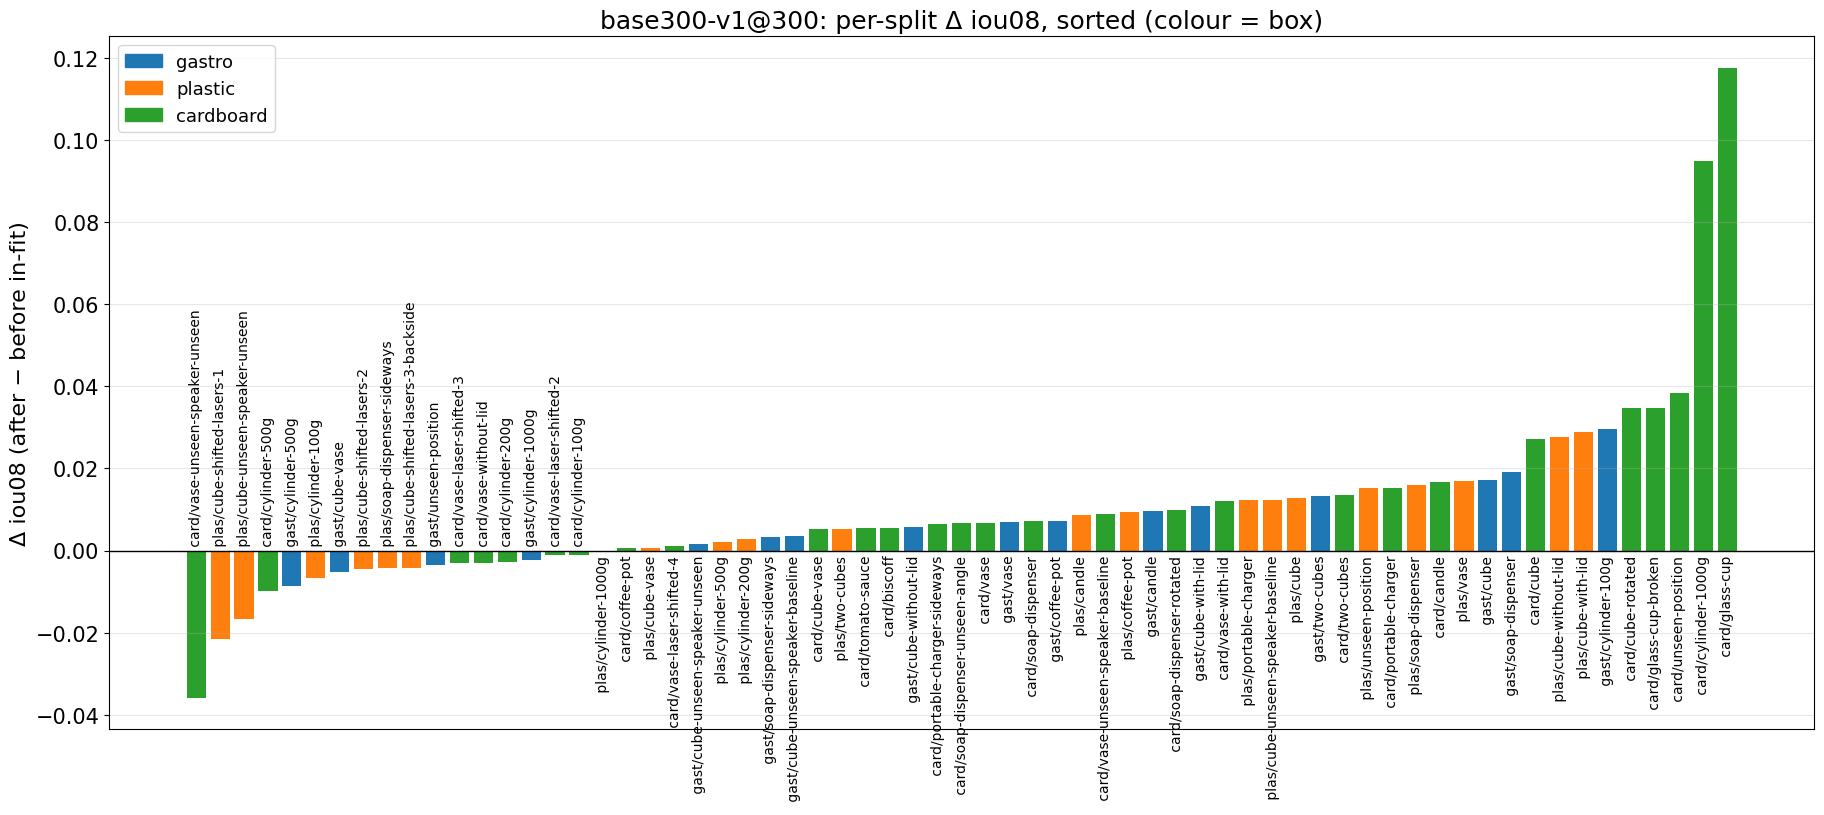

In [6]:
s = S.sort_values("d").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(22, 9))
ax.bar(range(len(s)), s.d, color=[BOXC[b] for b in s.box])
for i, r in s.iterrows():
    ax.text(i, 0, f" {r.box[:4]}/{r.split} ", rotation=90, ha="center", va="bottom" if r.d < 0 else "top", fontsize=10)
ax.axhline(0, c="k", lw=1); ax.set_xticks([])
ax.set(ylabel="Δ iou08 (after − before in-fit)", title=f"{TAG}: per-split Δ iou08, sorted (colour = box)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BOXC[b]) for b in BOXES], labels=BOXES); ax.grid(axis="y", alpha=.3); plt.show()

## Fig 3 · delta by category (box × category mean)

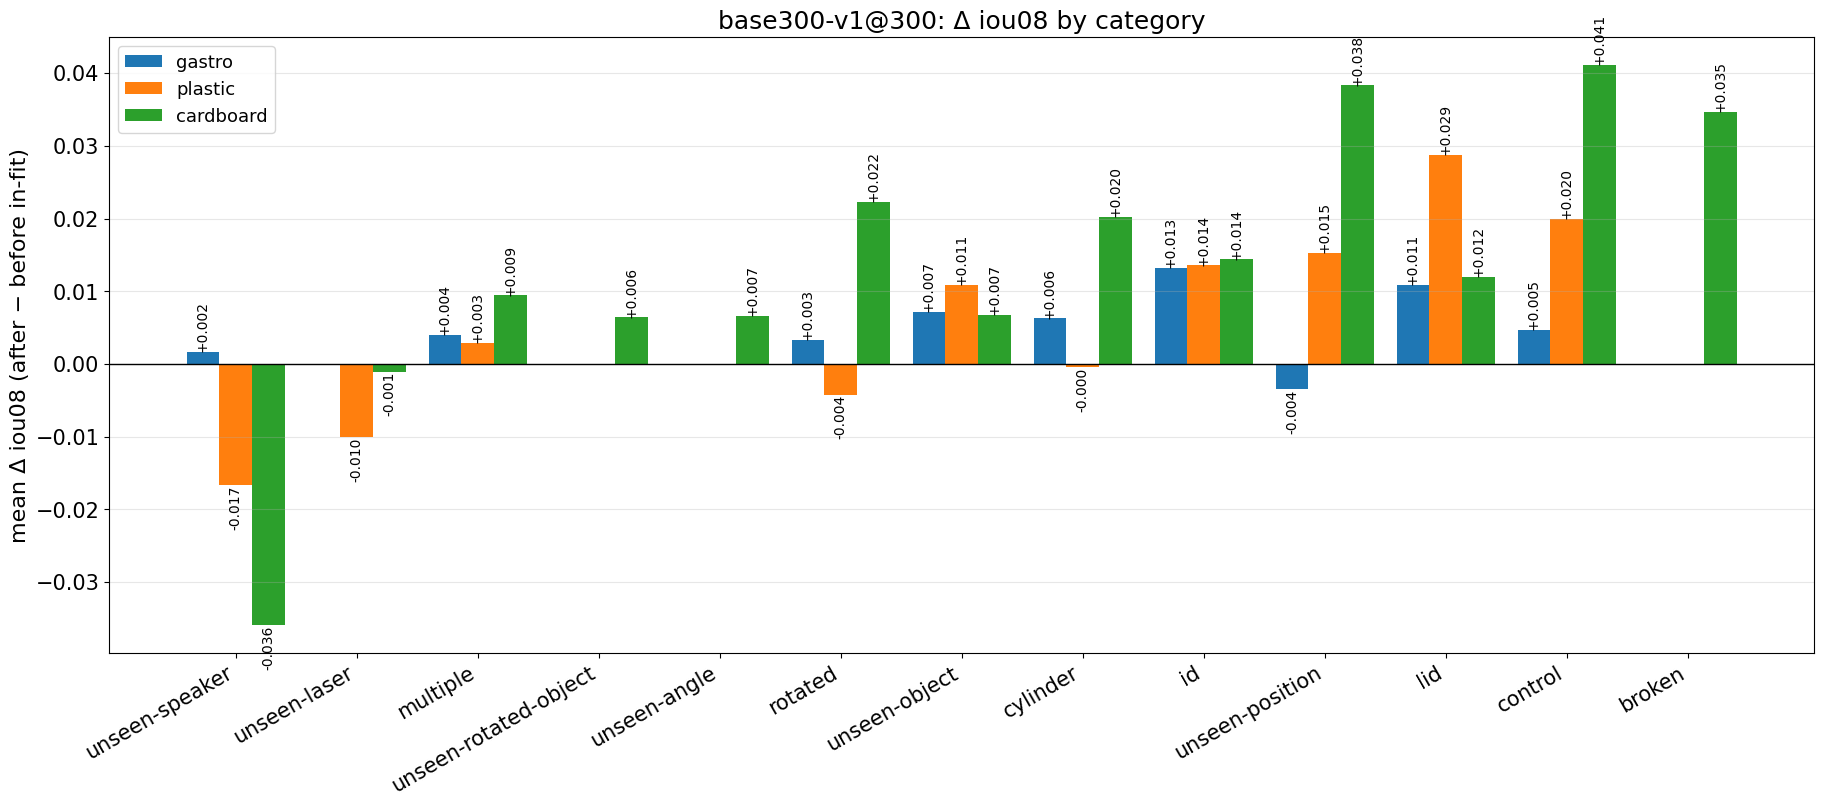

box                    gastro  plastic  cardboard
cat                                              
unseen-speaker         0.0017  -0.0167    -0.0359
unseen-laser              NaN  -0.0101    -0.0011
multiple               0.0041   0.0029     0.0094
unseen-rotated-object     NaN      NaN     0.0064
unseen-angle              NaN      NaN     0.0066
rotated                0.0033  -0.0042     0.0222
unseen-object          0.0072   0.0109     0.0068
cylinder               0.0063  -0.0005     0.0203
id                     0.0133   0.0136     0.0144
unseen-position       -0.0035   0.0153     0.0383
lid                    0.0109   0.0288     0.0120
control                0.0047   0.0200     0.0411
broken                    NaN      NaN     0.0347


In [7]:
G = S.groupby(["cat", "box"]).d.mean().unstack("box").reindex(columns=BOXES)
G = G.loc[G.mean(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(22, 8))
x, w = np.arange(len(G)), 0.27
for j, b in enumerate(BOXES):
    bars = ax.bar(x + (j - 1) * w, G[b], w, color=BOXC[b], label=b)
    for xi, v in zip(x + (j - 1) * w, G[b]):
        if not np.isnan(v): ax.text(xi, v, f"{v:+.3f}", ha="center", va="bottom" if v >= 0 else "top", fontsize=10, rotation=90)
ax.axhline(0, c="k", lw=1); ax.set_xticks(x, G.index, rotation=30, ha="right")
ax.set(ylabel="mean Δ iou08 (after − before in-fit)", title=f"{TAG}: Δ iou08 by category"); ax.legend(); ax.grid(axis="y", alpha=.3); plt.show()
print(G.round(4).to_string())

## Fig 4 · saved predictions: buggy post-fit (`ep0300`) vs eager (`ep0000`)
Old `runs/base300-v1/outputs_history/eval/<box>/<split>/ep0300-*.pt` were overwritten by the post-fit buggy eval; new ones are the eager re-eval (saved as ep0000 since eval-only doesn't restore the epoch). Same sample order is checked via sample/position/speaker ids.

In [8]:
def load(run, ep, b, sp):
    fs = sorted((ROOT / f"runs/{run}/outputs_history/eval/{b}/{sp}").glob(f"ep{ep:04d}-ba*.pt"))
    ds = [torch.load(f, map_location="cpu", weights_only=False) for f in fs]
    if not ds: return None
    p = torch.cat([d["mask_pred"].float() for d in ds]).numpy()
    ids = [(e, s, int(q), int(k)) for d in ds for e, s, q, k in zip(d["info"]["experiment"], d["info"]["sample_id"], d["info"]["position_id"], d["info"]["speaker"])]
    return p, ids
P, rows = {}, []
for b, sp in zip(S.box, S.split):
    o, n = load(RUN, EP, b, sp), load(f"{RUN}-reeval", 0, b, sp)
    if o is None or n is None or o[1] != n[1]: rows.append(dict(box=b, split=sp, comparable=False)); continue
    dp = np.abs(o[0] - n[0]); P[(b, sp)] = (o, n)
    rows.append(dict(box=b, split=sp, comparable=True, n=len(dp), max_dp=dp.max(), mean_dp=dp.mean(), frac_samples_changed=(dp.reshape(len(dp), -1).max(1) > 0.05).mean()))
DP = pd.DataFrame(rows)
print("comparable splits:", DP.comparable.sum(), "/", len(DP))
print(DP.sort_values("mean_dp", ascending=False).round(4).to_string(index=False))

comparable splits: 65 / 65
      box                          split  comparable   n  max_dp  mean_dp  frac_samples_changed
   gastro                      cube-vase        True  27  1.0000   0.0080                1.0000
cardboard                      glass-cup        True  12  0.9938   0.0046                1.0000
  plastic cube-shifted-lasers-3-backside        True  32  0.9873   0.0045                0.9688
cardboard                unseen-position        True  52  0.9993   0.0044                1.0000
cardboard                      two-cubes        True  79  1.0000   0.0043                1.0000
cardboard                   cube-rotated        True  20  1.0000   0.0035                1.0000
cardboard                      cube-vase        True  66  0.9926   0.0035                1.0000
  plastic                      cube-vase        True  32  0.9954   0.0035                1.0000
   gastro     cube-unseen-speaker-unseen        True  35  1.0000   0.0034                1.0000
cardboard    

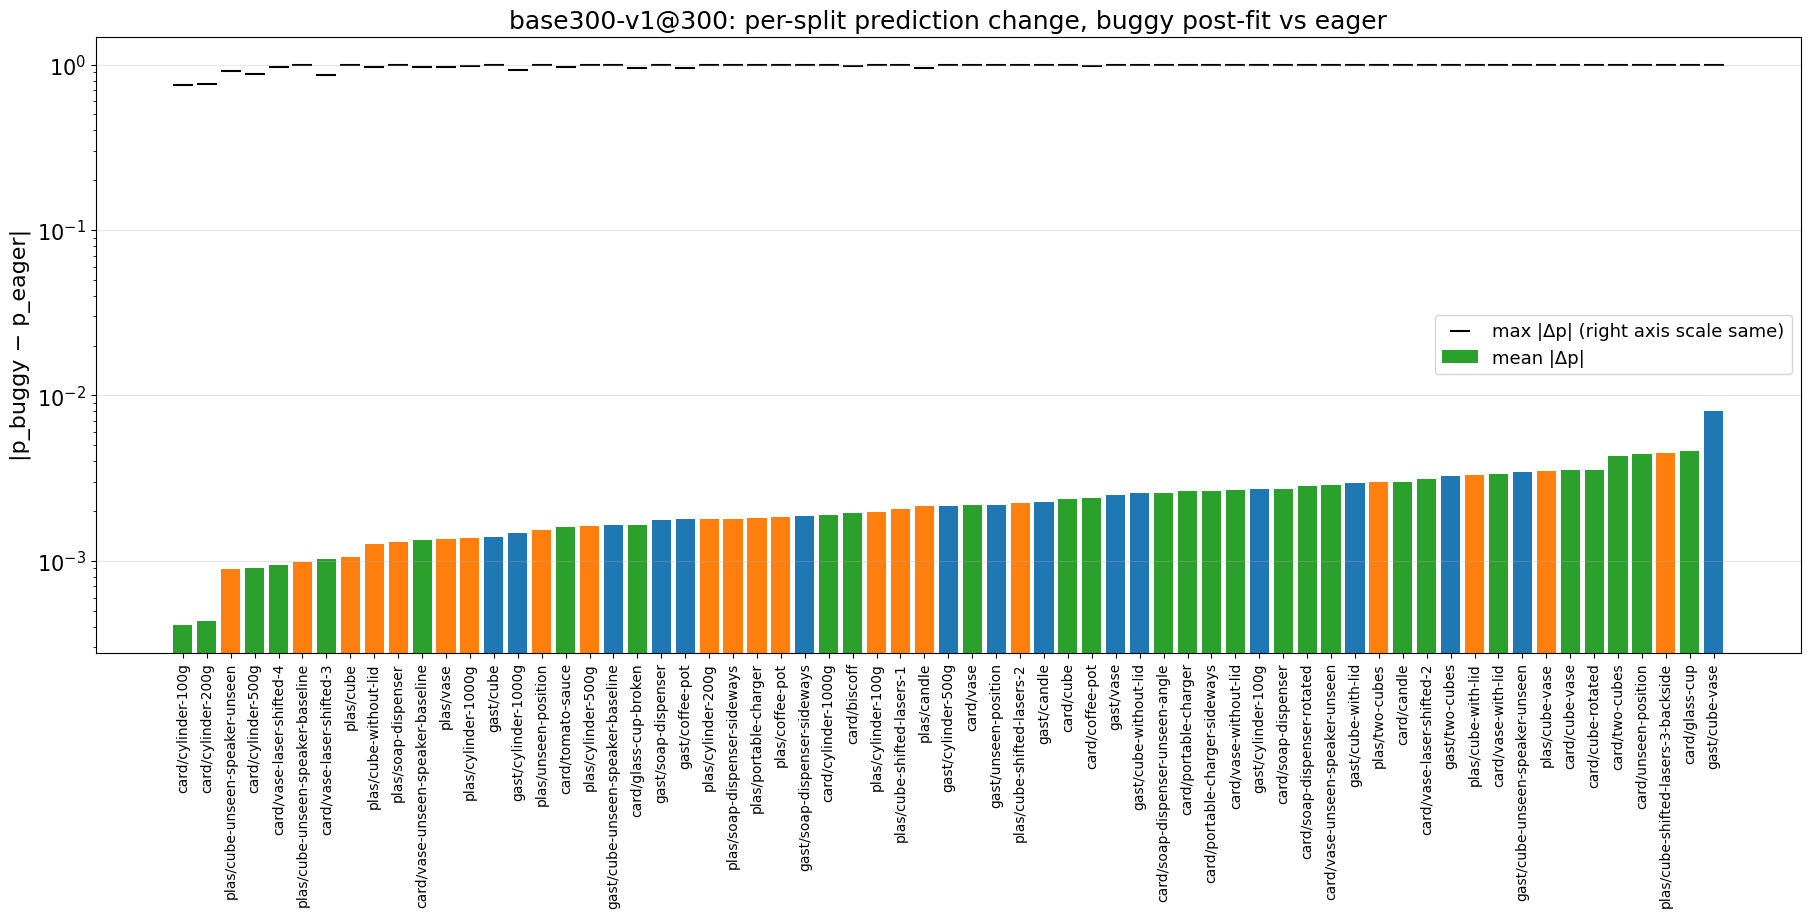

In [9]:
Q = DP[DP.comparable].sort_values("mean_dp")
fig, ax = plt.subplots(figsize=(22, 8))
ax.bar(range(len(Q)), Q.mean_dp, color=[BOXC[b] for b in Q.box], label="mean |Δp|")
ax.scatter(range(len(Q)), Q.max_dp, c="k", marker="_", s=200, label="max |Δp| (right axis scale same)")
ax.set_xticks(range(len(Q)), [f"{b[:4]}/{s}" for b, s in zip(Q.box, Q.split)], rotation=90, fontsize=10)
ax.set(yscale="log", ylabel="|p_buggy − p_eager|", title=f"{TAG}: per-split prediction change, buggy post-fit vs eager"); ax.legend(); ax.grid(axis="y", alpha=.3); plt.show()

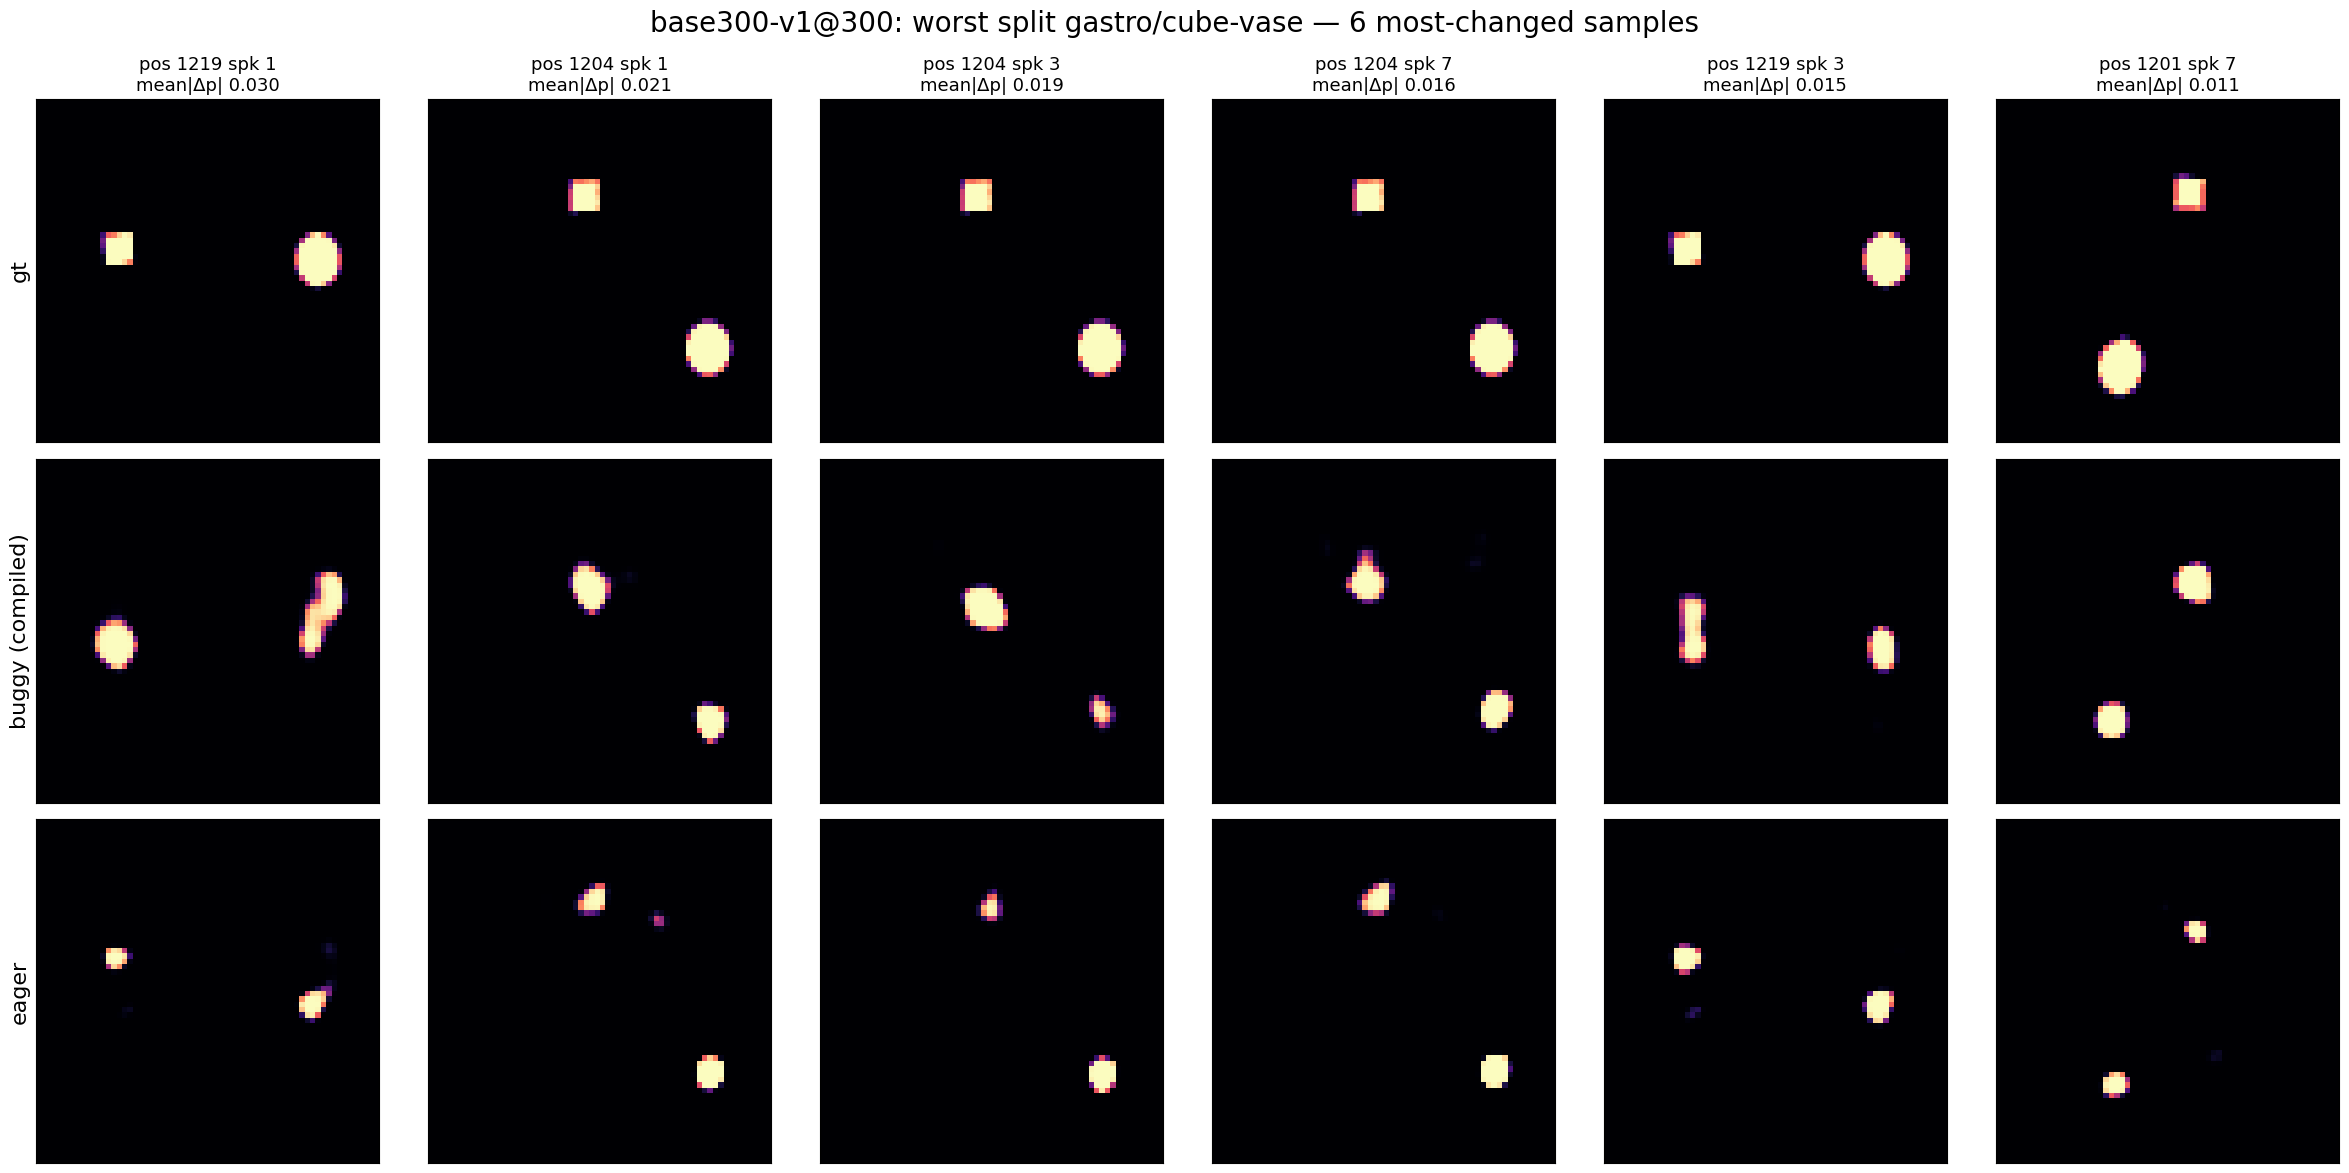

In [10]:
b, sp = Q.iloc[-1][["box", "split"]]
(po, ids), (pn, _) = P[(b, sp)]
dps = np.abs(po - pn).reshape(len(po), -1).mean(1)
pick = np.argsort(-dps)[:6]
fig, axs = plt.subplots(3, 6, figsize=(24, 12))
for j, i in enumerate(pick):
    e, s, q, k = ids[i]
    y = truth(e, s, q, k, *po.shape[-2:])
    for r, (img, lab) in enumerate([(y, "gt"), (po[i], "buggy (compiled)"), (pn[i], "eager")]):
        axs[r, j].imshow(img, vmin=0, vmax=1, cmap="magma"); axs[r, j].set_xticks([]); axs[r, j].set_yticks([])
        if j == 0: axs[r, j].set_ylabel(lab, fontsize=16)
    axs[0, j].set_title(f"pos {q} spk {k}\nmean|Δp| {dps[i]:.3f}", fontsize=13)
fig.suptitle(f"{TAG}: worst split {b}/{sp} — 6 most-changed samples", fontsize=20); plt.tight_layout(); plt.show()

## Summary

In [11]:
print(f"{TAG}, {len(S)} splits, iou08")
for c, lab in [("d", "after - before(in-fit)"), ("d_post", "after - before(post-fit)")]:
    print(f"  {lab:28s} mean Δ {S[c].mean():+.4f} | mean |Δ| {S[c].abs().mean():.4f} | # splits before < after: {(S[c] > 0).sum()}/{len(S)}")
print("  pooled iou08: " + ", ".join(f"{g}: {fit[g+'/iou08']:.4f} / {post[g+'/iou08']:.4f} -> {aft[g+'/iou08']:.4f}" for g in ["id", "ood"]) + "  (in-fit / post-fit -> eager)")

base300-v1@300, 65 splits, iou08
  after - before(in-fit)       mean Δ +0.0097 | mean |Δ| 0.0139 | # splits before < after: 47/65
  after - before(post-fit)     mean Δ +0.0076 | mean |Δ| 0.0112 | # splits before < after: 42/65
  pooled iou08: id: 0.6669 / 0.6684 -> 0.6800, ood: 0.3791 / 0.3810 -> 0.3848  (in-fit / post-fit -> eager)
